# Preamble

In [1]:
from IPython.core.magic import register_cell_magic


# Magic command to export to file
@register_cell_magic
def write_and_run(line, cell):
    argz = line.split()
    file = argz[-1]
    mode = "w"
    if len(argz) == 2 and argz[0] == "-a":
        mode = "a"
        cell = "\n# --- \n" + cell
    with open(file, mode, encoding="UTF-8") as f:
        f.write(cell)
    get_ipython().run_cell(cell)

In [ ]:
%%write_and_run output/preamble.py
from pathlib import Path

import cvxpy as cp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

from PIL import Image as image
from scipy.fft import dst, idst
from tqdm.auto import tqdm, trange

# from numpy import fft
from pyfftw.interfaces import numpy_fft as fft
import pyfftw

c:\Users\jeppe\Documents\MEGA\Base\DTU\02624 Inverse Problems and Imaging\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
%%write_and_run -a output/preamble.py
HW3_DIR = Path().resolve()
OUTPUT_DIR = Path("./output")
OUTPUT_DIR.mkdir(exist_ok=True)

mm = 1 / 25.4  # mm in inches
PAPER_WIDTH_IN = (210 - 15 - 25) * mm

EXPORT_DPI = 600

sns.set_theme(context="paper", style="whitegrid")
gray_norm = mpl.colors.Normalize(vmin=0, vmax=1)

In [4]:
%%write_and_run -a output/preamble.py
# Based on: https://stackoverflow.com/a/29261252/5036246
def sci_notation(number, sig_fig=2, latex_style=True, omit_coeff_if_unity=True):
    ret_string = "{0:.{1:d}e}".format(number, sig_fig)
    a, b = ret_string.split("e")

    # Calculate factor part
    factor = ""
    joiner = ""
    if omit_coeff_if_unity and float(a) == 1.0:
        factor = ""
        joiner = ""
    else:
        factor = a
        joiner = "×"

    # Calculate exponent part
    b = int(b)
    exponent = ""
    if latex_style:
        exponent = f"10^{{{str(b)}}}"
    else:
        exponent = f"10^{str(b)}"

    return factor + joiner + exponent

In [5]:
%%write_and_run -a output/preamble.py
pyfftw.interfaces.cache.enable()
pyfftw.interfaces.cache.set_keepalive_time(60.0)  # A minute

# Task 1
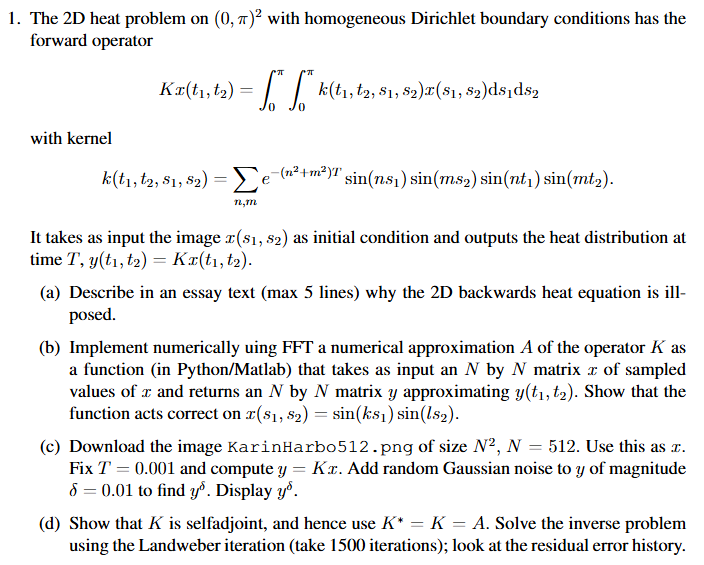

## 1.b
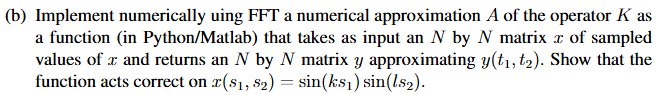

In [ ]:
%%write_and_run output/1_b_forward_operator.py
def forward_heat_operator(x: npt.NDArray, T: float) -> npt.NDArray:
    # An efficient way to solve this is to turn the convolution
    # into elementwise multiplication in the frequency domain
    # In Homework 2 we used DST, but here we are specifically asked to use FFT
    # So we follow odd-expansion as in Kim's given code (ModelProblems)

    N = x.shape[0]
    assert N == x.shape[1], "Input must be square"

    # Spatial scale
    ds = np.pi / (N + 1)

    # Wavenumbers
    N_ext = 2 * (N + 1)
    frequencies = fft.fftfreq(N_ext, d=ds)
    wavenumbers = 2 * np.pi * frequencies
    n = wavenumbers
    m = wavenumbers
    n_grid, m_grid = np.meshgrid(n, m, indexing="ij")

    # Decay factors
    k2 = n_grid**2 + m_grid**2  # Combined wavenumber
    decay_factors = np.exp(-(k2) * T)  # Here the same as eigvals or singvals

    # Construct odd expansion (Pad with zeros, reflect and negate)
    x_ext = np.zeros((N_ext, N_ext))  # Pad
    x_ext[1:N+1, 1:N+1] = x  # Insert original
    x_ext[N+2:, 1:N+1] = -np.flipud(x)  # Reflect along horizontal
    x_ext[:, N+2:] = -np.fliplr(x_ext[:, 1:N+1])  # Reflect along vertical

    # Carry out convolution in frequency domain
    x_ext_hat = fft.fft2(x_ext)
    x_ext_hat_T = x_ext_hat * decay_factors
    y_ext = fft.ifft2(x_ext_hat_T)

    y = y_ext[1:N+1, 1:N+1]

    # Optionally, if we care about being normalised:
    # Scaling factor due to basis functions sin(...) not being normalised
    # scaling_factor = (np.pi / 2)**2
    # y = y * scaling_factor
    return np.real(y)


Text(0.5, 1.0, 'Difference (computed - expected)')

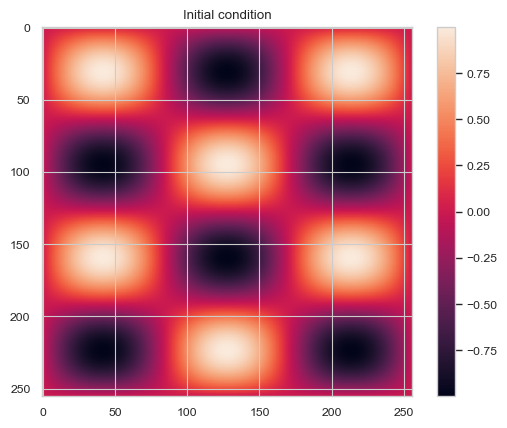

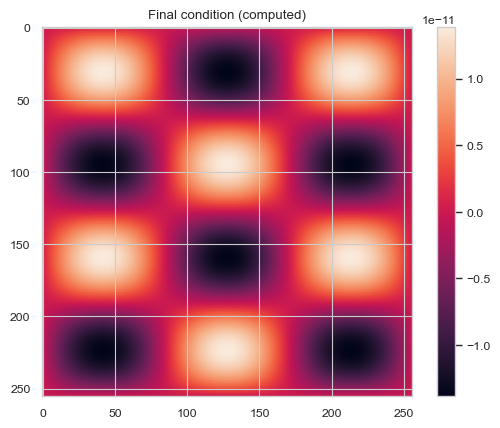

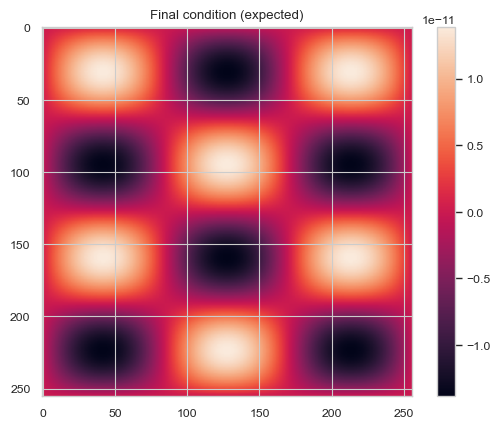

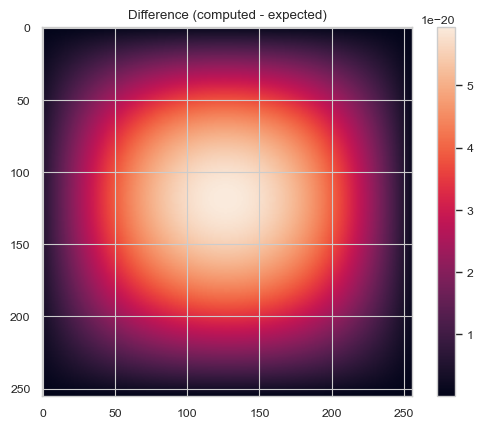

In [33]:
%%write_and_run output/1_b_test.py
# Construct test case from task
N = 256
k = 4
l = 3
T = 1

# Homogenous so don't store endpoints
ds = np.pi / (N + 1)
s_1 = np.arange(ds, np.pi, ds)
s_2 = s_1.copy()
s1_grid, s2_grid = np.meshgrid(s_1, s_2, indexing="ij")
x_initial = np.sin(k * s1_grid) * np.sin(l * s2_grid)
y_final = forward_heat_operator(x_initial, T=T)

# Test:
# Since only the k-lth mode is non-zero, only this mode is propagated
decay = np.exp(-(k**2 + l**2) * T)

# Optionally, if we care about being normalised:
# integral_scaling = (np.pi / 2)**2
# y_expected = x_initial * decay * integral_scaling
y_expected = x_initial * decay

plt.figure()
plt.imshow(x_initial)
plt.colorbar()
plt.title("Initial condition")

plt.figure()
plt.imshow(y_final)
plt.colorbar()
plt.title("Final condition (computed)")

plt.figure()
plt.imshow(y_expected)
plt.colorbar()
plt.title("Final condition (expected)")

plt.figure()
plt.imshow(y_final - y_expected)
plt.colorbar()
plt.title("Difference (computed - expected)")


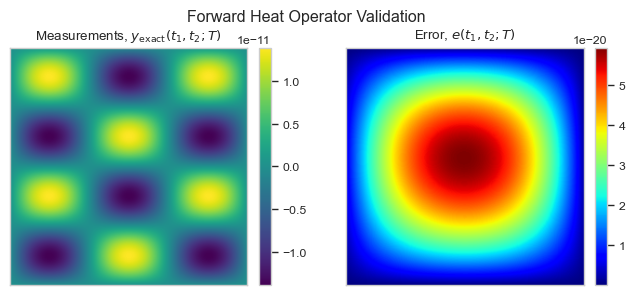

In [34]:
%%write_and_run -a output/1_b_test.py
fig, (ax, ax_error) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2 - 0.5))

img = ax.imshow(y_expected, plt.cm.viridis)
ax.set_title("Measurements, $y_\\text{exact}(t_1, t_2; T)$")
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# https://stackoverflow.com/questions/18195758/set-matplotlib-colorbar-size-to-match-graph
plt.colorbar(img, ax=ax, fraction=0.046, pad=0.04)
img_error = ax_error.imshow(y_final - y_expected, plt.cm.jet)
ax_error.set_title("Error, $e(t_1, t_2; T)$")
ax_error.set_aspect('equal')
ax_error.set_xticks([])
ax_error.set_yticks([])
plt.colorbar(img_error, ax=ax_error, fraction=0.046, pad=0.04)

fig.tight_layout()
fig.suptitle("Forward Heat Operator Validation", y=1.02)

plt.savefig(OUTPUT_DIR / "1_b.png", dpi=EXPORT_DPI, bbox_inches='tight')

## 1.c
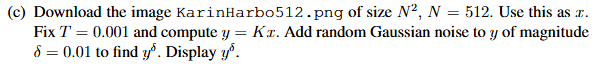

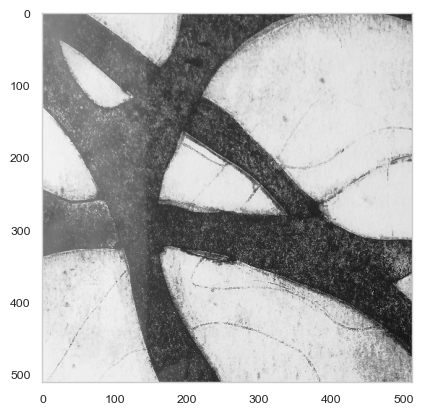

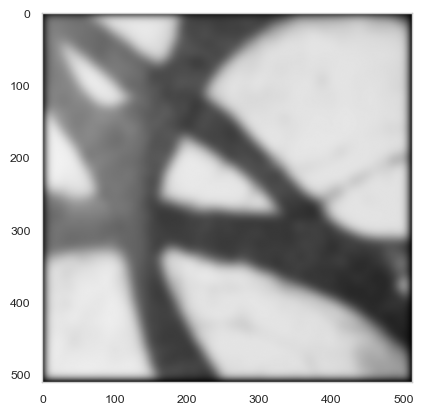

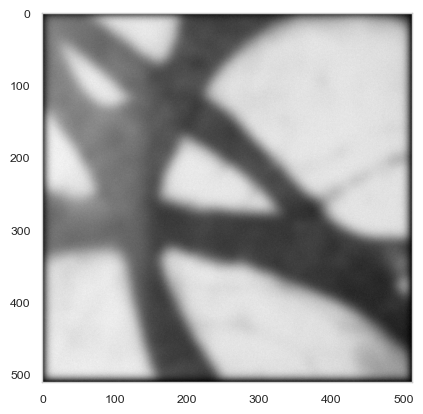

In [ ]:
%%write_and_run output/1_c.py
img = image.open(HW3_DIR / "KarinHarbo512.png").convert("L")
x = np.asarray(img) / 255.0

T = 0.001
y = forward_heat_operator(x, T=T)

plt.figure()
plt.imshow(x, cmap='gray', norm=gray_norm)
plt.grid(False)
plt.figure()
plt.grid(False)
plt.imshow(y, cmap='gray', norm=gray_norm)

np.random.seed(42)
noise = np.random.normal(0, 0.01, size=y.shape)
y_noisy = y + noise
plt.figure()
plt.grid(False)
plt.imshow(y_noisy, cmap='gray', norm=gray_norm)

# plt.figure()
# plt.grid(False)
# plt.imshow(y - y_noisy, cmap='gray')


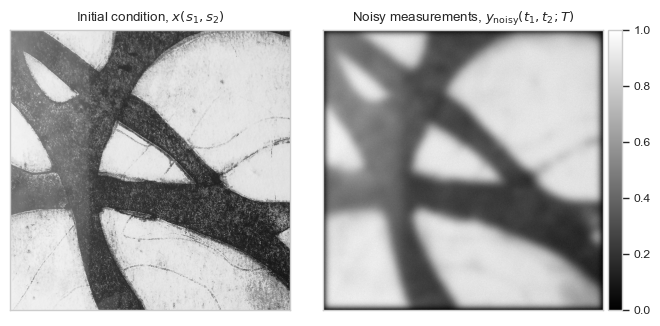

In [ ]:
%%write_and_run -a output/1_c.py
fig, (ax_x, ax_y_noisy) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2 - 0.1), sharex=True)

img_x = ax_x.imshow(x, cmap='gray', norm=gray_norm)
img_y_noisy = ax_y_noisy.imshow(y_noisy, cmap='gray', norm=gray_norm)

for ax in (ax_x, ax_y_noisy):
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])

# Add colorbars to both axes so they have equal size
# https://stackoverflow.com/questions/18195758/set-matplotlib-colorbar-size-to-match-graph
divider_x = make_axes_locatable(ax_x)
cax_x = divider_x.append_axes("right", size="5%", pad=0.05)
cax_x.axis('off')  # Hide the left colorbar axis

divider_y = make_axes_locatable(ax_y_noisy)
cax_y = divider_y.append_axes("right", size="5%", pad=0.05)
plt.colorbar(img_y_noisy, cax=cax_y)

ax_x.set_title("Initial condition, $x(s_1, s_2)$")
ax_y_noisy.set_title("Noisy measurements, $y_\\text{noisy}(t_1, t_2; T)$")

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "1_c.png", dpi=EXPORT_DPI, bbox_inches='tight')

## 1.d
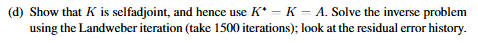

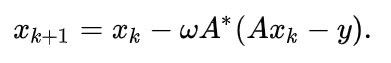

In [ ]:
%%write_and_run output/1_d.py
# Since operator is self adjoint, we can easily implement Landweber

def landweber_iteration(x_k, y_noisy, T, omega):
    A_x_k = forward_heat_operator(x_k, T=T)
    return x_k - omega * forward_heat_operator(A_x_k - y_noisy, T=T)

# Largest singular value corresponds to the lowest frequency mode
# exp(-(k^2 + l^2) * T) with k=l=1
singular_value_max = np.exp(-2 * (1**2) * T)
omega = 0.9 * (2 / (singular_value_max**2))  # Safety margin
print(omega)
x_k = y_noisy.copy()
history = [x_k.copy()]
# N_iter = 1500
N_iter = 1500
for i in trange(N_iter):
    x_k = landweber_iteration(x_k, y_noisy, T, omega)
    history.append(x_k.copy())


1.8072144192192154


 13%|█▎        | 191/1500 [00:29<03:23,  6.42it/s]

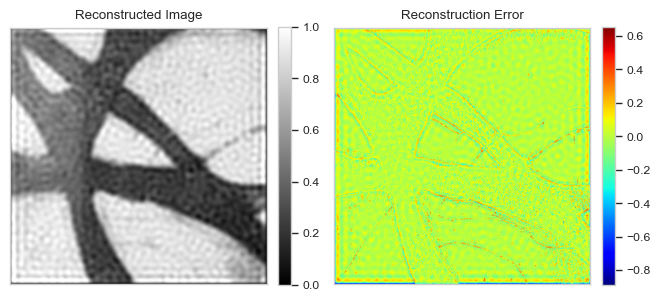

In [ ]:
%%write_and_run -a output/1_d.py
fig, (ax_recon, ax_error) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2 - 0.1), sharex=True)

img_recon = ax_recon.imshow(history[-1], cmap='gray', norm=gray_norm)
img_error = ax_error.imshow(history[-1] - x, cmap='jet')
plt.colorbar(img_recon, ax=ax_recon, fraction=0.046, pad=0.04)
plt.colorbar(img_error, ax=ax_error, fraction=0.046, pad=0.04)

for ax in (ax_recon, ax_error):
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])

ax_recon.set_title("Reconstructed Image")
ax_error.set_title("Reconstruction Error")

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "1_d_images.png", dpi=EXPORT_DPI, bbox_inches='tight')

In [ ]:
%%write_and_run -a output/1_d.py
data = []
for i, x_k in enumerate(tqdm(history)):
    error_L2 = np.linalg.norm(x_k - x, ord=2) / np.linalg.norm(x, ord=2)
    error_Linf = np.linalg.norm(x_k - x, ord=np.inf) / np.linalg.norm(x, ord=np.inf)
    data.append({"Iteration": i, "Relative Error L2": error_L2, "Relative Error Linf": error_Linf})

df = pd.DataFrame(data)


100%|██████████| 1501/1501 [01:44<00:00, 14.42it/s]


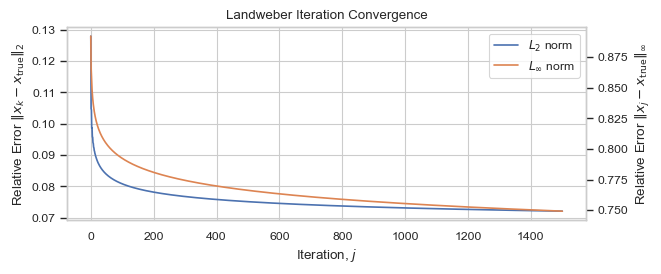

In [ ]:
%%write_and_run -a output/1_d.py
plt.figure(figsize =(PAPER_WIDTH_IN, 2.5))

ax1 = plt.gca()
ax2 = ax1.twinx()

sns.lineplot(data=df, x="Iteration", y="Relative Error L2", label="$L_2$ norm", c="C0", ax=ax1)
sns.lineplot(data=df, x="Iteration", y="Relative Error Linf", label="$L_∞$ norm", c="C1", ax=ax2)

ax1.set_ylabel(r"Relative Error $\|x_k - x_\text{true}\|_2$")
ax2.set_ylabel(r"Relative Error $\|x_j - x_\text{true}\|_∞$")

# Collect labels in one legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')
ax2.legend_.remove()

ax2.grid(False)

plt.title("Landweber Iteration Convergence")
ax1.set_xlabel("Iteration, $j$")

plt.savefig(OUTPUT_DIR / "1_d_convergence.png", dpi=EXPORT_DPI, bbox_inches='tight')

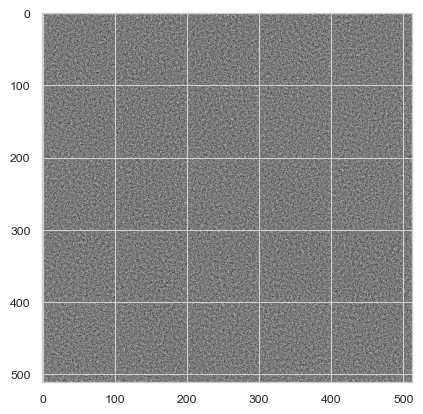

In [ ]:
from scipy.sparse.linalg import LinearOperator, lsqr, cg, cgs, gmres

x_shape = y_noisy.shape
n_features = np.prod(x_shape) # Total number of pixels

# SciPy solvers work with flat 1D vectors, so we reshape inside.
def mv_forward(x_flat):
    """Computes A * x"""
    x_2d = x_flat.reshape(x_shape)
    # Apply your heat operator
    res = forward_heat_operator(x_2d, T)
    return res.flatten()

def mv_adjoint(y_flat):
    """Computes A.T * y (The Transpose)"""
    y_2d = y_flat.reshape(x_shape)

    # Since A^† = A
    res = forward_heat_operator(y_2d, T)
    return res.flatten()

A = LinearOperator(
    shape=(n_features, n_features),
    matvec=mv_forward,
    rmatvec=mv_adjoint,
)


result = cg(A, y_noisy.flatten(), maxiter=3)
result = gmres(A, y_noisy.flatten(), maxiter=3)

# 5. Reshape the result back to image
x_restored = result[0].reshape(x_shape)

plt.imshow(x_restored, cmap='gray')

# Task 2
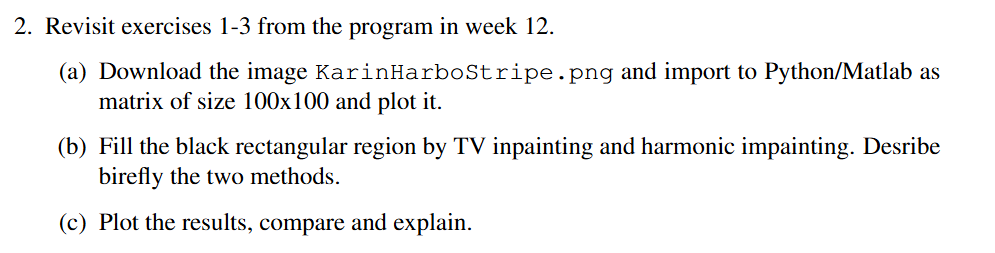

## 2.a
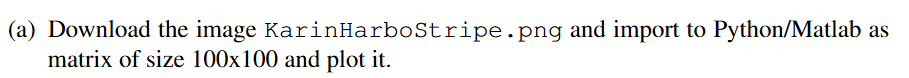

In [ ]:
%%write_and_run output/2_a.py
N = 100
img = image.open(HW3_DIR / "KarinHarboStripe.png").convert("L")
x = np.asarray(img) / 255.0

assert x.shape == (N, N)


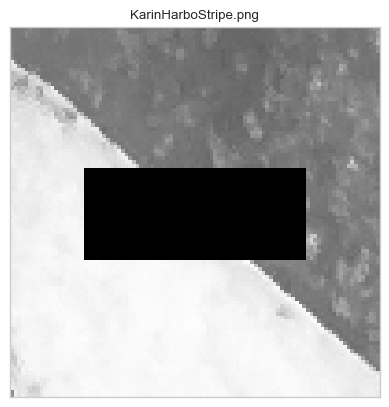

In [ ]:
%%write_and_run -a output/2_a.py
plt.figure()
plt.imshow(x, cmap='gray', norm=gray_norm)
plt.xticks([])
plt.yticks([])
plt.title("KarinHarboStripe.png")

plt.savefig(OUTPUT_DIR / "2_a.png", dpi=EXPORT_DPI, bbox_inches='tight')

## 2.b
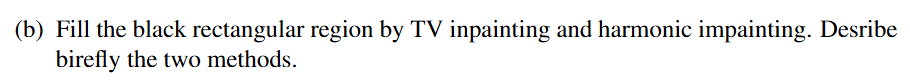

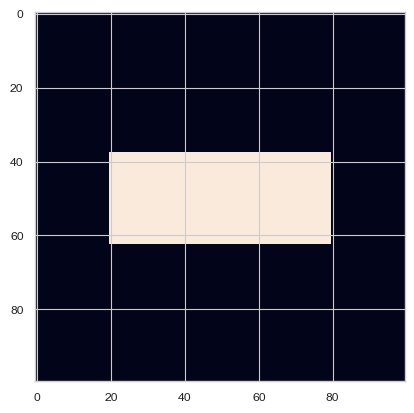

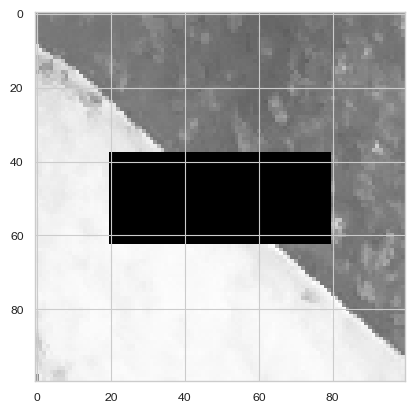

In [ ]:
%%write_and_run output/2_b.py
# Generate mask
mask = x == 0.0

x_inpaint = x.copy()
# x_inpaint[mask] = 0.5  # Initial guess, start at gray
plt.figure()
plt.imshow(mask)
plt.figure()
plt.imshow(x_inpaint, cmap='gray', norm=gray_norm)

# x_


### 2.b TV

In [ ]:
%%write_and_run -a output/2_b.py
u = cp.Variable((N, N))

z = x_inpaint.copy()
M = (~mask).astype(np.float64)

fidelity = 0.5 * cp.sum_squares(cp.multiply(M, u - z))
regularisation = cp.tv(u)

lambda_ = 0.01
objective = cp.Minimize(fidelity + lambda_ * regularisation)
problem = cp.Problem(objective)
result = problem.solve()

u_sol_tv = u.value.copy()

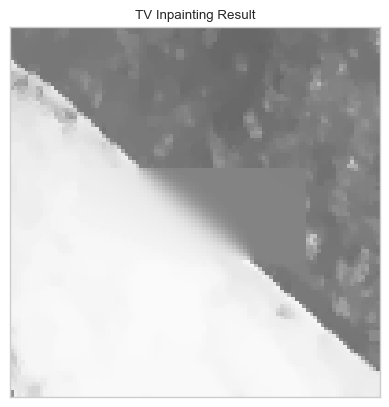

In [ ]:
%%write_and_run -a output/2_b.py
plt.imshow(u_sol_tv, cmap='gray', norm=gray_norm)
plt.xticks([])
plt.yticks([])
plt.title("TV Inpainting Result")
plt.savefig(OUTPUT_DIR / "2_b_tv.png", dpi=EXPORT_DPI, bbox_inches='tight')



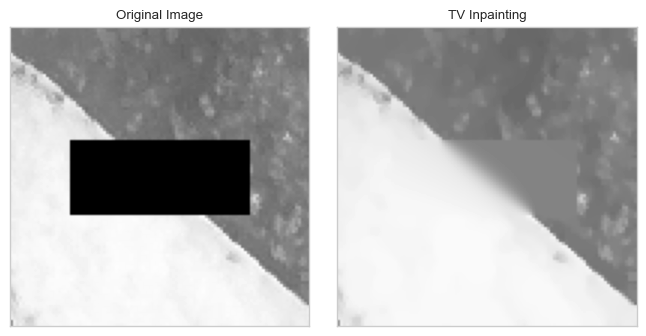

In [ ]:
%%write_and_run -a output/2_b.py
fig, (ax_orig, ax_inpaint) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2))

img = ax_orig.imshow(x_inpaint, cmap="gray", norm=gray_norm)
ax_orig.set_title("Original Image")
ax_orig.set_aspect('equal')
ax_orig.set_xticks([])
ax_orig.set_yticks([])

img_inpaint = ax_inpaint.imshow(u_sol_tv, cmap="gray", norm=gray_norm)
ax_inpaint.set_title("TV Inpainting")
ax_inpaint.set_aspect('equal')
ax_inpaint.set_xticks([])
ax_inpaint.set_yticks([])

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "2_b_tv_noisy_comparison.png", dpi=EXPORT_DPI, bbox_inches='tight')

### 2.b TV noiseless

In [ ]:
%%write_and_run -a output/2_b.py
u = cp.Variable((N, N))
objective = cp.Minimize(cp.tv(u))
constraint = [u[~mask] == x_inpaint[~mask]]
problem = cp.Problem(objective, constraint)
result = problem.solve()

u_sol_tv_noiseless = u.value.copy()

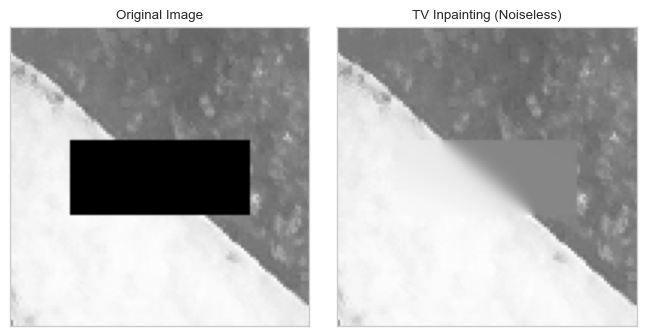

In [ ]:
%%write_and_run -a output/2_b.py
fig, (ax_orig, ax_inpaint) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2))

img = ax_orig.imshow(x_inpaint, cmap="gray", norm=gray_norm)
ax_orig.set_title("Original Image")
ax_orig.set_aspect('equal')
ax_orig.set_xticks([])
ax_orig.set_yticks([])

img_inpaint = ax_inpaint.imshow(u_sol_tv_noiseless, cmap="gray", norm=gray_norm)
ax_inpaint.set_title("TV Inpainting (Noiseless)")
ax_inpaint.set_aspect('equal')
ax_inpaint.set_xticks([])
ax_inpaint.set_yticks([])

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "2_b_tv_noiseless_comparison.png", dpi=EXPORT_DPI, bbox_inches='tight')

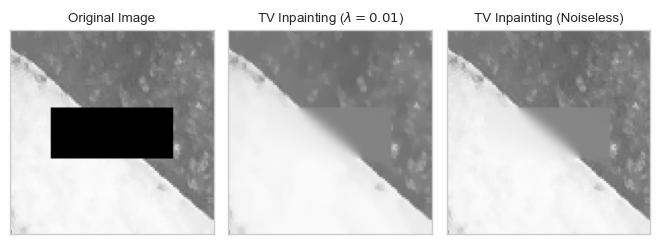

In [ ]:
%%write_and_run -a output/2_b.py
fig, axs = plt.subplots(1, 3, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2))

img = ax_orig.imshow(x_inpaint, cmap="gray", norm=gray_norm)
axs[0].imshow(x_inpaint, cmap="gray", norm=gray_norm)
axs[0].set_title("Original Image")

axs[1].imshow(u_sol_tv, cmap="gray", norm=gray_norm)
axs[1].set_title("TV Inpainting ($λ=0.01$)")

axs[2].imshow(u_sol_tv_noiseless, cmap="gray", norm=gray_norm)
axs[2].set_title("TV Inpainting (Noiseless)")

for ax in axs:
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "2_b_tv_comparison.png", dpi=EXPORT_DPI, bbox_inches='tight')

### 2.b Harmonic

In [ ]:
%%write_and_run -a output/2_b.py
# Harmonic
u = cp.Variable((N, N))

z = x_inpaint.copy()
M = (~mask).astype(np.float64)
fidelity = 0.5 * cp.sum_squares(cp.multiply(M, u - z))

grad_u_x = cp.diff(u, axis=0)
grad_u_y = cp.diff(u, axis=1)
regularisation =  0.5 * (cp.sum_squares(grad_u_x) + cp.sum_squares(grad_u_y))

lambda_ = 0.1
objective = cp.Minimize(fidelity + lambda_ * regularisation)
problem = cp.Problem(objective)
result = problem.solve()

u_sol_harmonic = u.value.copy()

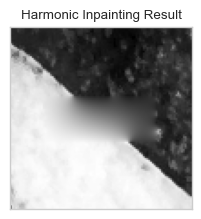

In [ ]:
%%write_and_run -a output/2_b.py
plt.figure(figsize = (60 * mm, 60 * mm))
plt.imshow(u_sol_harmonic, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.title("Harmonic Inpainting Result")
plt.savefig(OUTPUT_DIR / "2_b_harmonic.png", dpi=EXPORT_DPI, bbox_inches='tight')

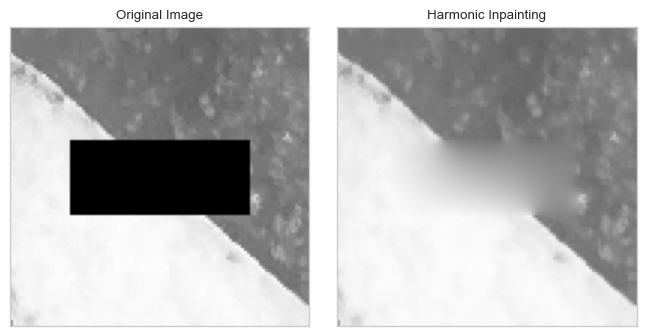

In [ ]:
%%write_and_run -a output/2_b.py
fig, (ax_orig, ax_inpaint) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2))

img = ax_orig.imshow(x_inpaint, cmap="gray", norm=gray_norm)
ax_orig.set_title("Original Image")
ax_orig.set_aspect('equal')
ax_orig.set_xticks([])
ax_orig.set_yticks([])

img_inpaint = ax_inpaint.imshow(u_sol_harmonic, cmap="gray", norm=gray_norm)
ax_inpaint.set_title("Harmonic Inpainting")
ax_inpaint.set_aspect('equal')
ax_inpaint.set_xticks([])
ax_inpaint.set_yticks([])

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "2_b_harmonic_noisy_comparison.png", dpi=EXPORT_DPI, bbox_inches='tight')

### 2.b Harmonic noiseless

In [ ]:
%%write_and_run -a output/2_b.py
u = cp.Variable((N, N))
grad_u_x = cp.diff(u, axis=0)
grad_u_y = cp.diff(u, axis=1)
objective = cp.Minimize(cp.sum_squares(grad_u_x) + cp.sum_squares(grad_u_y))
constraint = [u[~mask] == x_inpaint[~mask]]
problem = cp.Problem(objective, constraint)
result = problem.solve()

u_sol_harmonic_noiseless = u.value.copy()


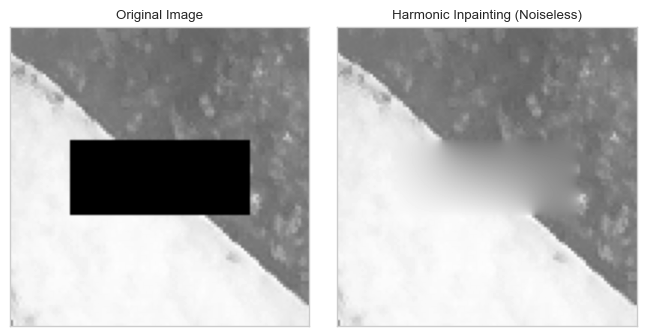

In [ ]:
%%write_and_run -a output/2_b.py
fig, (ax_orig, ax_inpaint) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2))

img = ax_orig.imshow(x_inpaint, cmap="gray", norm=gray_norm)
ax_orig.set_title("Original Image")
ax_orig.set_aspect('equal')
ax_orig.set_xticks([])
ax_orig.set_yticks([])

img_inpaint = ax_inpaint.imshow(u_sol_harmonic_noiseless, cmap="gray", norm=gray_norm)
ax_inpaint.set_title("Harmonic Inpainting (Noiseless)")
ax_inpaint.set_aspect('equal')
ax_inpaint.set_xticks([])
ax_inpaint.set_yticks([])

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "2_b_harmonic_noiseless_comparison.png", dpi=EXPORT_DPI, bbox_inches='tight')

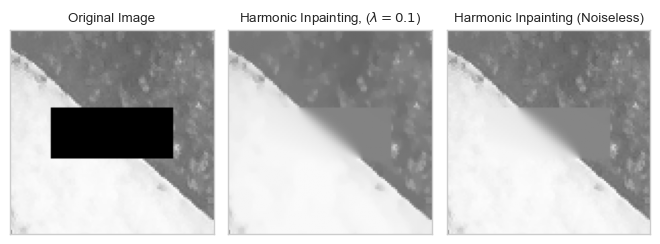

In [ ]:
%%write_and_run -a output/2_b.py
fig, axs = plt.subplots(1, 3, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN / 2))

img = ax_orig.imshow(x_inpaint, cmap="gray", norm=gray_norm)
axs[0].imshow(x_inpaint, cmap="gray", norm=gray_norm)
axs[0].set_title("Original Image")

axs[1].imshow(u_sol_tv, cmap="gray", norm=gray_norm)
axs[1].set_title("Harmonic Inpainting, ($λ=0.1$)")

axs[2].imshow(u_sol_tv_noiseless, cmap="gray", norm=gray_norm)
axs[2].set_title("Harmonic Inpainting (Noiseless)")

for ax in axs:
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "2_b_harmonic_comparison.png", dpi=EXPORT_DPI, bbox_inches='tight')

## 2.c
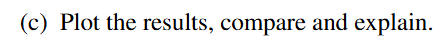

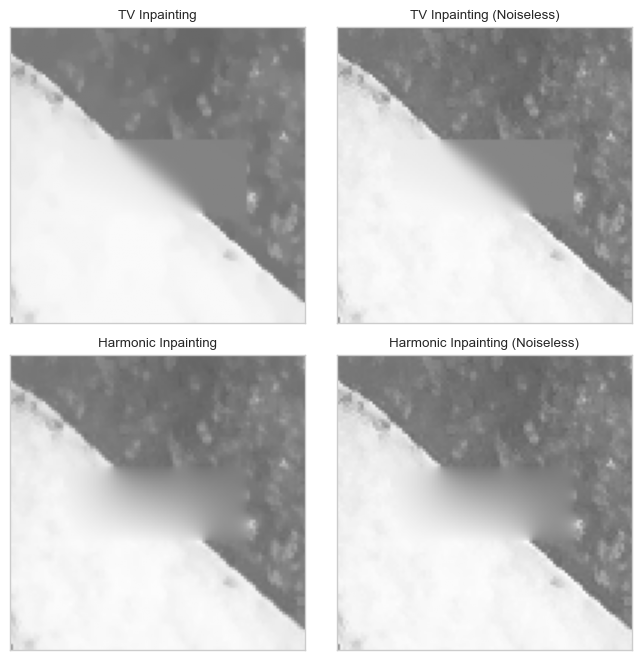

In [ ]:
%%write_and_run output/2_c.py
fig, axs = plt.subplots(2, 2, figsize=(PAPER_WIDTH_IN, PAPER_WIDTH_IN))

axs[0, 0].imshow(u_sol_tv, cmap="gray", norm=gray_norm)
axs[0, 0].set_title("TV Inpainting")

axs[0, 1].imshow(u_sol_tv_noiseless, cmap="gray", norm=gray_norm)
axs[0, 1].set_title("TV Inpainting (Noiseless)")

axs[1, 0].imshow(u_sol_harmonic, cmap="gray", norm=gray_norm)
axs[1, 0].set_title("Harmonic Inpainting")

axs[1, 1].imshow(u_sol_harmonic_noiseless, cmap="gray", norm=gray_norm)
axs[1, 1].set_title("Harmonic Inpainting (Noiseless)")

for ax in axs.flatten():
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "2_c.png", dpi=EXPORT_DPI, bbox_inches='tight')